# AdaBoost - classificação da ocorrência de chuva

Aplicação do algoritmo AdaBoost para classificar a ocorrência de chuva em Caruaru.

- Classe positiva: `SIM = 1`
- Classe negativa: `NAO = 0`
- Divisão temporal: 80% para treino e 20% para teste

## Referência teórica

Aula 08 - Tópicos em Big Data com Python, páginas 87 a 102: stumps, reaponderação das amostras, voto ponderado e `AdaBoostClassifier`.

## 1. Importações

O AdaBoost combina vários classificadores simples. Neste projeto, cada classificador-base é um *decision stump*: uma árvore de decisão com apenas uma divisão (`max_depth=1`).

In [1]:
# inspect permite verificar a assinatura do AdaBoost em cada versão do scikit-learn.
import inspect
# time mede o custo de treinamento e da busca de hiperparâmetros.
import time

# matplotlib desenha as matrizes de confusão e o gráfico de importâncias.
import matplotlib.pyplot as plt
# pandas lê o CSV e organiza as tabelas apresentadas no notebook.
import pandas as pd
# sklearn identifica a versão efetivamente utilizada nesta execução.
import sklearn
# ColumnTransformer aplica a preparação somente às colunas numéricas selecionadas.
from sklearn.compose import ColumnTransformer
# AdaBoostClassifier implementa o boosting sequencial estudado na Aula 08.
from sklearn.ensemble import AdaBoostClassifier
# SimpleImputer preenche valores ausentes sem usar informações do teste.
from sklearn.impute import SimpleImputer
# As métricas avaliam acertos e erros para as duas classes.
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, f1_score, matthews_corrcoef,
    precision_score, recall_score,
)
# Estes objetos fazem a validação cronológica e a busca sem tocar no teste.
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
# Pipeline une preparação e modelo para prevenir vazamento de dados.
from sklearn.pipeline import Pipeline
# DecisionTreeClassifier(max_depth=1) cria o stump usado como aprendiz fraco.
from sklearn.tree import DecisionTreeClassifier

# Mostra a versão para registrar a compatibilidade da execução.
print('scikit-learn:', sklearn.__version__)
# Mostra se a versão usa o nome estimator ou base_estimator.
print('Parâmetros de AdaBoostClassifier:', list(inspect.signature(AdaBoostClassifier).parameters))

scikit-learn: 1.9.1
Parâmetros de AdaBoostClassifier: ['estimator', 'n_estimators', 'learning_rate', 'random_state']


## 2. Base de dados, atributos, alvo e divisão temporal

A base contém medições meteorológicas de Caruaru. O modelo usa as variáveis do clima para identificar se houve chuva em cada registro. Os dados mais antigos formam o treino e os mais recentes ficam reservados para o teste.

In [2]:
# Define o caminho da base adaptada usada na classificação.
caminho = '../dataset/INMET_NE_PE_A341_CARUARU_01-01-2025_A_31-12-2025_ADAPTADO.CSV'
# Lê o CSV com a codificação usada pelo projeto.
df = pd.read_csv(caminho, encoding='iso-8859-1')
# Remove a coluna vazia quando ela estiver presente, sem falhar caso ela não exista.
df = df.drop(columns=['Unnamed: 19'], errors='ignore')

# Extrai os quatro dígitos da hora UTC para formar uma coluna temporal completa.
hora = df['Hora UTC'].str.extract(r'(\d{4})')[0]
# Combina data e hora no formato reconhecido pelo pandas.
df['DATA_HORA'] = pd.to_datetime(df['Data'] + ' ' + hora, format='%Y-%m-%d %H%M')
# Ordena os registros cronologicamente antes de separar treino e teste.
df = df.sort_values('DATA_HORA').reset_index(drop=True)
# Cria o mês como atributo de sazonalidade.
df['MES'] = df['DATA_HORA'].dt.month
# Cria a hora do dia como atributo do comportamento horário.
df['HORA'] = df['DATA_HORA'].dt.hour
# Converte SIM em 1 e NAO em 0 para a classificação binária.
df['CHUVA_BINARIA'] = (df['CHUVA'] == 'SIM').astype(int)

# Lista identificadores temporais e alvos que não podem entrar como atributos.
colunas_remover = ['Data', 'Hora UTC', 'DATA_HORA', 'CHUVA', 'CHUVA_BINARIA']
# X contém somente as variáveis preditoras meteorológicas e sazonais.
X = df.drop(columns=colunas_remover)
# y contém somente a resposta que o modelo precisa aprender.
y = df['CHUVA_BINARIA']

# Define o corte cronológico: 80% inicial para treino e 20% final para teste.
ponto_corte = int(len(df) * 0.80)
# Mantém os registros mais antigos no treino e os mais recentes no teste.
X_train, X_test = X.iloc[:ponto_corte], X.iloc[ponto_corte:]
# Mantém os rótulos alinhados às mesmas linhas de X.
y_train, y_test = y.iloc[:ponto_corte], y.iloc[ponto_corte:]

# Exibe o tamanho e o fim do intervalo usado para treinar.
print(f'Treino: {len(X_train)} registros; último horário: {df.loc[ponto_corte - 1, "DATA_HORA"]}')
# Exibe o período posterior isolado exclusivamente para a avaliação final.
print(f'Teste: {len(X_test)} registros; de {df.loc[ponto_corte, "DATA_HORA"]} até {df.loc[len(df) - 1, "DATA_HORA"]}')
# Mostra o desbalanceamento de chuva antes de qualquer treinamento.
print(f'Chuva no treino: {y_train.mean():.2%}; no teste: {y_test.mean():.2%}')
# Confere que as variáveis preditoras ficaram consistentes após a separação.
assert list(X.columns) == list(df.drop(columns=colunas_remover).columns)

Treino: 7008 registros; último horário: 2025-10-19 23:00:00
Teste: 1752 registros; de 2025-10-20 00:00:00 até 2025-12-31 23:00:00
Chuva no treino: 18.45%; no teste: 1.54%


## 3. AdaBoost inicial

Conforme a Aula 08 (págs. 87, 94 e 99-102), os stumps são treinados em sequência; os erros recebem mais peso e os votos são ponderados. A imputação fica dentro do `Pipeline`, portanto é aprendida somente com cada partição de treino.

In [3]:
# Seleciona explicitamente as colunas numéricas disponíveis no conjunto de treino.
colunas_numericas = X_train.select_dtypes(include='number').columns.tolist()
# Define a imputação dentro do pipeline para que a mediana seja aprendida só no treino.
preparacao = ColumnTransformer([
    # add_indicator preserva a informação de que um valor estava ausente.
    ('numericas', SimpleImputer(strategy='median', add_indicator=True), colunas_numericas),
])

# Cria o AdaBoost de forma compatível com versões novas e antigas do scikit-learn.
def criar_adaboost(estimator, n_estimators=50, learning_rate=1.0, random_state=42):
    # Agrupa os parâmetros que têm o mesmo nome nas duas versões da biblioteca.
    parametros = dict(n_estimators=n_estimators, learning_rate=learning_rate, random_state=random_state)
    # Versões atuais chamam o classificador-base de estimator.
    if 'estimator' in inspect.signature(AdaBoostClassifier).parameters:
        return AdaBoostClassifier(estimator=estimator, **parametros)
    # Versões antigas chamavam o mesmo parâmetro de base_estimator.
    return AdaBoostClassifier(base_estimator=estimator, **parametros)

# Define um stump: uma árvore com uma única divisão, como apresentado na Aula 08.
stump_inicial = DecisionTreeClassifier(max_depth=1, random_state=42)
# Reúne a preparação e o AdaBoost em um único objeto reproduzível.
pipeline_ada = Pipeline([
    # Primeira etapa: preenche ausências sem consultar o teste.
    ('preparacao', preparacao),
    # Segunda etapa: treina 50 stumps com taxa de aprendizado padrão.
    ('modelo', criar_adaboost(stump_inicial, n_estimators=50, learning_rate=1.0, random_state=42)),
])

# Marca o início do cronômetro do treinamento inicial.
inicio = time.perf_counter()
# Ajusta o pipeline somente com os registros cronologicamente anteriores.
pipeline_ada.fit(X_train, y_train)
# Calcula a duração do ajuste sem incluir a avaliação do teste.
tempo_treino_inicial = time.perf_counter() - inicio
# Mostra o tempo para documentação e comparação de custo.
print(f'Modelo inicial treinado em {tempo_treino_inicial:.3f} s')

Modelo inicial treinado em 0.398 s


## 4. Validação cruzada temporal somente no treino

`TimeSeriesSplit(n_splits=5, gap=24)` preserva a ordem e cria um intervalo de 24 horas entre treino e validação. O teste cronológico reservado não participa nem desta etapa nem da busca. O critério de seleção é F1 para `SIM=1`, adequado para avaliar a classe menos frequente sem depender só da acurácia.

In [4]:
# Cria cinco divisões em ordem cronológica e deixa uma janela de 24 horas entre elas.
cv_temporal = TimeSeriesSplit(n_splits=5, gap=24)
# Cria uma lista para documentar a composição de cada fold.
resumo_folds = []
# Percorre as divisões usando exclusivamente o conjunto de treino.
for numero, (indices_treino, indices_validacao) in enumerate(cv_temporal.split(X_train), start=1):
    # Registra tamanho e quantidade de ocorrências de chuva em cada parte.
    resumo_folds.append({
        'fold': numero,
        'treino': len(indices_treino),
        'validação': len(indices_validacao),
        'SIM no treino': int(y_train.iloc[indices_treino].sum()),
        'SIM na validação': int(y_train.iloc[indices_validacao].sum()),
    })
# Exibe a auditoria dos folds antes de calcular as pontuações.
display(pd.DataFrame(resumo_folds))

# Mede F1 da classe positiva em cópias do pipeline, sem consultar o teste final.
scores_inicial = cross_val_score(
    pipeline_ada, X_train, y_train, cv=cv_temporal, scoring='f1', n_jobs=1, error_score='raise'
)
# Exibe o F1 obtido em cada período de validação.
display(pd.DataFrame({'fold': range(1, 6), 'F1 de SIM na validação': scores_inicial}))
# Resume a média e a variação temporal do modelo inicial.
print(f'F1 médio inicial: {scores_inicial.mean():.2%} (+/- {scores_inicial.std():.2%})')

,fold,treino,validação,SIM no treino,SIM na validação
0,1,1144,1168,103,105
1,2,2312,1168,208,161
2,3,3480,1168,363,392
3,4,4648,1168,751,357
4,5,5816,1168,1107,175


,fold,F1 de SIM na validação
0,1,0.424581
1,2,0.350230
2,3,0.541063
3,4,0.713065
4,5,0.625287


F1 médio inicial: 53.08% (+/- 13.13%)


## 5. Busca de hiperparâmetros sem consultar o teste

A grade explora o classificador-base (`estimator`), `n_estimators`, `learning_rate` e `random_state`. Ambos os estimadores são stumps (`max_depth=1`), mantendo a definição da aula. A busca ajusta o melhor candidato novamente em todo o treino.

In [5]:
# Primeiro stump candidato: uma divisão e folhas com pelo menos uma observação.
stump_1 = DecisionTreeClassifier(max_depth=1, random_state=42)
# Segundo stump candidato: mesma profundidade, porém com duas observações mínimas por folha.
stump_2 = DecisionTreeClassifier(max_depth=1, min_samples_leaf=2, random_state=42)
# Define o nome correto do parâmetro-base para a versão instalada da biblioteca.
prefixo_estimator = 'modelo__estimator' if 'estimator' in inspect.signature(AdaBoostClassifier).parameters else 'modelo__base_estimator'

# Define as combinações testadas; o prefixo modelo__ acessa o AdaBoost dentro do Pipeline.
param_grid = {
    prefixo_estimator: [stump_1, stump_2],
    'modelo__n_estimators': [50, 100],
    'modelo__learning_rate': [0.5, 1.0],
    'modelo__random_state': [42],
}

# Cria a busca usando somente o treino e o mesmo F1 da validação temporal.
busca = GridSearchCV(
    estimator=pipeline_ada, param_grid=param_grid, scoring='f1', cv=cv_temporal,
    n_jobs=1, refit=True, error_score='raise', return_train_score=False,
)
# Inicia a medição do tempo gasto em todos os ajustes da grade.
inicio = time.perf_counter()
# Testa as combinações e reajusta o melhor resultado em todo o treino.
busca.fit(X_train, y_train)
# Calcula a duração da busca completa.
tempo_busca = time.perf_counter() - inicio
# Recupera o pipeline já ajustado com a melhor combinação encontrada.
modelo_otimizado = busca.best_estimator_
# Exibe os hiperparâmetros selecionados pela validação temporal.
print('Melhores parâmetros:', busca.best_params_)
# Exibe o F1 médio de validação do melhor candidato.
print(f'F1 médio da CV temporal: {busca.best_score_:.2%}')
# Exibe o custo computacional da busca.
print(f'Tempo da busca: {tempo_busca:.3f} s')

Melhores parâmetros: {'modelo__estimator': DecisionTreeClassifier(max_depth=1, random_state=42), 'modelo__learning_rate': 1.0, 'modelo__n_estimators': 100, 'modelo__random_state': 42}
F1 médio da CV temporal: 55.36%
Tempo da busca: 14.832 s


## 6. Avaliação final no teste cronológico reservado

A classe positiva é `SIM=1`. Na matriz, linhas são valores reais e colunas previsões, na ordem `[NAO=0, SIM=1]`: `[[VN, FP], [FN, VP]]`. Especificidade é o recall da classe negativa. Nenhuma métrica é usada para escolher hiperparâmetros depois desta célula.

,Acurácia,Precisão SIM,Recall SIM,Especificidade,F1 SIM,MCC
AdaBoost inicial,98.74%,69.23%,33.33%,99.77%,45.00%,0.4751
AdaBoost ajustado,98.80%,87.50%,25.93%,99.94%,40.00%,0.4726


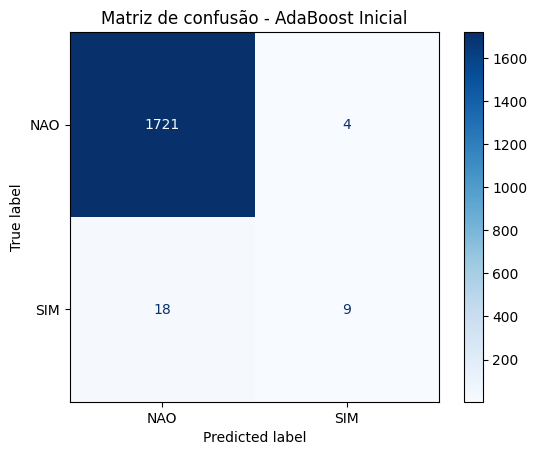

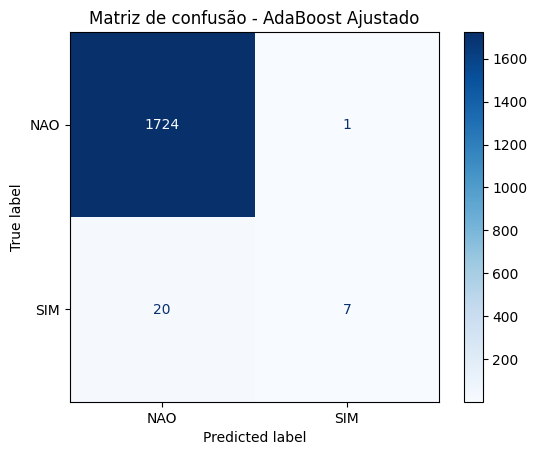

In [6]:
# Cria uma função reutilizável para calcular todas as métricas solicitadas.
def calcular_metricas(y_real, y_previsto):
    # Retorna cada medida em uma estrutura que será transformada em tabela.
    return {
        # Mede a proporção total de classificações corretas.
        'Acurácia': accuracy_score(y_real, y_previsto),
        # Mede quantos alertas de chuva previstos eram realmente chuva.
        'Precisão SIM': precision_score(y_real, y_previsto, pos_label=1, zero_division=0),
        # Mede quantas ocorrências reais de chuva foram identificadas.
        'Recall SIM': recall_score(y_real, y_previsto, pos_label=1, zero_division=0),
        # Mede quantas ocorrências de ausência de chuva foram identificadas.
        'Especificidade': recall_score(y_real, y_previsto, pos_label=0, zero_division=0),
        # Equilibra precisão e recall para a classe SIM.
        'F1 SIM': f1_score(y_real, y_previsto, pos_label=1, zero_division=0),
        # Resume a qualidade considerando simultaneamente as duas classes.
        'MCC': matthews_corrcoef(y_real, y_previsto),
    }

# Gera previsões do modelo inicial no teste que permaneceu isolado.
pred_inicial = pipeline_ada.predict(X_test)
# Gera previsões do modelo escolhido pela busca no mesmo teste.
pred_otimizado = modelo_otimizado.predict(X_test)
# Organiza as métricas dos dois ajustes em linhas comparáveis.
resultados = pd.DataFrame({
    'AdaBoost inicial': calcular_metricas(y_test, pred_inicial),
    'AdaBoost ajustado': calcular_metricas(y_test, pred_otimizado),
}).T

# Cria uma cópia apenas para formatação, preservando os valores numéricos originais.
exibicao = resultados.copy()
# Formata MCC com quatro casas e as demais medidas como percentuais.
for coluna in exibicao.columns:
    exibicao[coluna] = exibicao[coluna].map('{:.4f}'.format if coluna == 'MCC' else '{:.2%}'.format)
# Mostra a tabela final de avaliação.
display(exibicao)

# Desenha uma matriz de confusão para cada versão avaliada.
for nome, previsoes in {'Inicial': pred_inicial, 'Ajustado': pred_otimizado}.items():
    # Fixa a ordem das classes como NAO=0 e SIM=1.
    ConfusionMatrixDisplay.from_predictions(
        y_test, previsoes, labels=[0, 1], display_labels=['NAO', 'SIM'], cmap='Blues'
    )
    # Define o título correspondente ao modelo exibido.
    plt.title(f'Matriz de confusão - AdaBoost {nome}')
    # Exibe o gráfico criado.
    plt.show()

## 7. Importância dos atributos e votos dos stumps

`feature_importances_` resume as reduções de impureza e não estabelece causalidade. Atributos correlacionados podem repartir importância. Os pesos e erros dos estimadores correspondem, respectivamente, à “voz” ($\alpha$) e ao erro ponderado explicados nas páginas 90-94 e 100-102.

,importância
atributo,
"UMIDADE RELATIVA DO AR, HORARIA (%)",28.50%
UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),27.79%
HORA,11.93%
TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),6.81%
MES,5.17%
PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),5.09%
missingindicator_RADIACAO GLOBAL (Kj/m²),3.99%
"VENTO, DIREÇÃO HORARIA (gr) (° (gr))",3.65%
RADIACAO GLOBAL (Kj/m²),3.15%


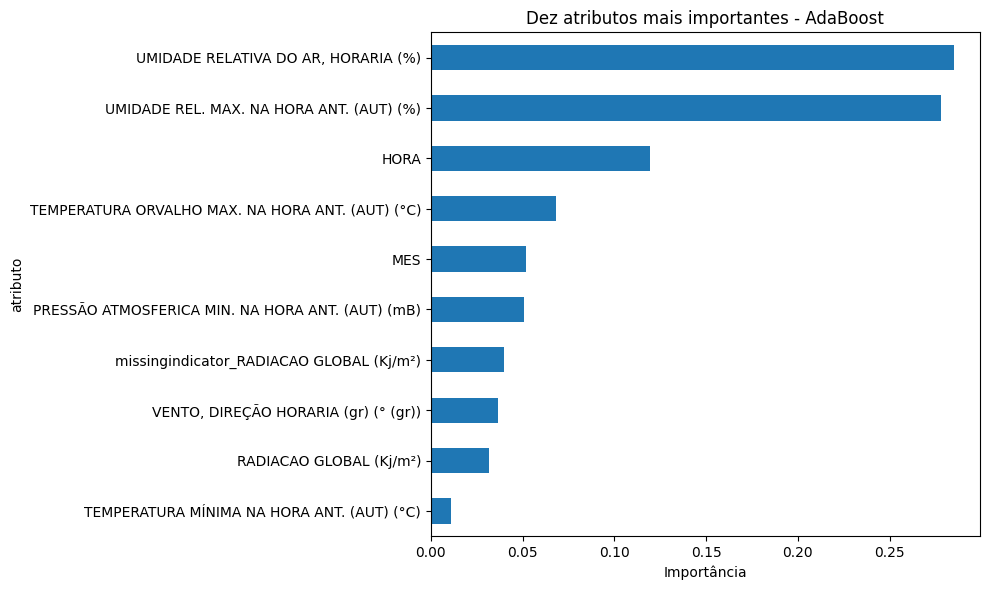

,stump,peso do voto (alpha),erro ponderado
0,1,1.486129,0.184503
1,2,1.245394,0.223498
2,3,0.574536,0.360191
3,4,0.326604,0.419067
4,5,0.481263,0.381954
5,6,0.340061,0.415795
6,7,0.559121,0.363751
7,8,0.374362,0.407487
8,9,0.388497,0.404079
9,10,0.342949,0.415093


In [7]:
modelo_final = modelo_otimizado.named_steps['modelo']
nomes_atributos = modelo_otimizado.named_steps['preparacao'].get_feature_names_out()
importancias = (
    pd.Series(modelo_final.feature_importances_, index=nomes_atributos)
    .sort_values(ascending=False)
    .rename_axis('atributo')
    .to_frame('importância')
)
importancias.index = importancias.index.str.replace('numericas__', '', regex=False)
display(importancias.head(10).style.format({'importância': '{:.2%}'}))
importancias.head(10).sort_values('importância').plot.barh(legend=False, figsize=(10, 6))
plt.xlabel('Importância')
plt.title('Dez atributos mais importantes - AdaBoost')
plt.tight_layout()
plt.show()

diagnostico_stumps = pd.DataFrame({
    'stump': range(1, len(modelo_final.estimators_) + 1),
    'peso do voto (alpha)': modelo_final.estimator_weights_,
    'erro ponderado': modelo_final.estimator_errors_,
})
display(diagnostico_stumps.head(10))

## 8. Conclusão da execução

A interpretação deve priorizar F1, recall de `SIM`, especificidade e MCC. A acurácia isolada pode ocultar o efeito do desbalanceamento entre as classes.